# Incomplete Gamma function

This notebook shows the Incomplete Gamma Function $\Gamma(0, 2 \, \Delta z \, k_{\varepsilon})$ (Gradshteyn and Ryzhik, 2007, p. 899) as a function of $\Delta z$ and $k_{\varepsilon}$. The results are computed via numerical integration and by using [`scipy.special`](https://docs.scipy.org/doc/scipy/reference/special.html).

##### References

* Gradshteyn, I. S., and I. M. Ryzhik, 2007, Table of integrals, series, and products, 7 ed.:
Elsevier. (Translated from Russian by Scripta Technica, Inc.).

In [1]:
import numpy as np
from scipy.special import gammainc, gamma
from scipy.integrate import quad
from matplotlib import pyplot as plt

In [2]:
from numpy.testing import assert_almost_equal

In [3]:
# Function for evaluating the integrand of the required Incomplete Gamma Function
def integrand(k, Dz):
    return np.exp(-2*Dz*k)/k

In [4]:
# cut-off wavenumber and distance from continuatioj plane and top of the sources
k_epsilon = 0.01
Dz = 100.

In [5]:
# result obtained via numerical integration
result1, error = quad(integrand, k_epsilon, np.inf, args=(Dz))

In [6]:
result1, error

(0.04890051070806089, 8.692433761332263e-10)

In [7]:
# result obtained via scipy.special
a = 1e-7
result2 = gamma(a)*(1. - gammainc(a, 2*Dz*k_epsilon))

In [8]:
result2

0.048900515256650526

In [9]:
# comparison
assert_almost_equal(result1, result2, decimal=8)

#### Plot $\varepsilon \times k$

In [27]:
k = np.linspace(1e-7, 0.02, 100)

In [35]:
a = 1e-3
Dz = 100.
epsilon = []
for ki in k:
    epsilon.append(gamma(a)*(1. - gammainc(a, 2*Dz*ki)))
epsilon = np.array(epsilon)

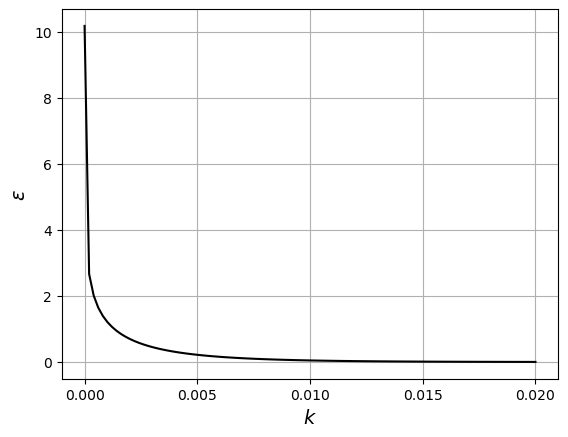

In [36]:
plt.figure()
plt.plot(k, epsilon, 'k-')
plt.xlabel('$k$', fontsize=14)
plt.ylabel('$\\varepsilon$', fontsize=14)
plt.xticks(np.linspace(0, 0.02, 5))
plt.grid()
plt.show()